In [37]:
# Import the packages
import re

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder
from sklearn.pipeline import Pipeline
from sklearn import set_config

import joblib
from pathlib import Path

pd.set_option("display.max_colwidth", None)

# Load the feature engineered Data for France 2025 (cleaned)

In [38]:
df_2025 = pd.read_csv("../data/processed/EU/2025_FR_cleaned.csv")
# Clean column headers (removes accidental spaces)
df_2025.columns = df_2025.columns.str.strip()

# Check dataset dimensions and view first few rows
print(f"Dataset shape: {df_2025.shape[0]} rows, {df_2025.shape[1]} columns")
df_2025.head()
display(df_2025.head())
display(df_2025.info())

Dataset shape: 90001 rows, 23 columns


,VFN,Mh,Tan,T,Va,Ve,Mk,Cn,Ct,m (kg),...,ec (cm3),ep (KW),z (Wh/km),IT,Erwltp (g/km),Fuel consumption,RLFI,Electric range (km),r,Ewltp (g/km)
0,IP-0-SCC-1,LOTUS,E4*2018/858*00092*02,TYPE131,1B,1,LOTUS,EMIRA,M1,1575.0,...,3456.0,298.0,0.0,none,0.00,11.4,RL-NA,0.0,1,258.0
1,IP-000000000EUM182-ZN6-1,MASERATI,E3*2018/858*00056*02,M182,0AGT630BC8,5D4A441D5,MASERATI,GRECALE TROFEO,M1,2107.0,...,2992.0,390.0,0.0,e3 37,1.56,11.2,RL-2021_0297-ZN6-1,0.0,1,254.0
2,IP-000000000EUM189-ZAM-1,MASERATI,E3*2018/858*00084*06,M189,1AGT630CC8,5E5AN21N4B,MASERATI,GRANTURISMO,M1,1870.0,...,2992.0,404.0,0.0,e3 28 29 37,1.56,10.1,RL-03_M189_MAS39-ZAM,0.0,1,228.0
3,IP-00000001-LFZ,LEAPMOTOR,E5*2018/858*00324*03,B11,0100,B565116,LEAPMOTOR,C10,M1,2025.0,...,1499.0,65.0,205.0,none,0.00,0.4,RL-0000000000001-LFZ,124.0,462,10.0
4,IP-0000000101-LFZ,LEAPMOTOR,E5*2018/858*00324*04,B11,0100,B565116,LEAPMOTOR,C10,M1,2025.0,...,1499.0,65.0,205.0,none,0.00,0.4,RL-0000000000001-LFZ,129.0,53,10.0


<class 'pandas.DataFrame'>
RangeIndex: 90001 entries, 0 to 90000
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   VFN                  90001 non-null  str    
 1   Mh                   90001 non-null  str    
 2   Tan                  90001 non-null  str    
 3   T                    89982 non-null  str    
 4   Va                   90001 non-null  str    
 5   Ve                   90000 non-null  str    
 6   Mk                   90001 non-null  str    
 7   Cn                   90001 non-null  str    
 8   Ct                   90001 non-null  str    
 9   m (kg)               90001 non-null  float64
 10  Mt                   90001 non-null  float64
 11  Ft                   90001 non-null  str    
 12  Fm                   90001 non-null  str    
 13  ec (cm3)             90001 non-null  float64
 14  ep (KW)              90001 non-null  float64
 15  z (Wh/km)            90001 non-null  float64
 1

None

## Let's drop the **r** column:

In [39]:
# # Drop non-predictive identifiers like 'ID' if present
# if 'r' in df_2025.columns:
#     df_2025 = df_2025.drop(columns=['r'])

# df_2025.head()


# Let's see the distributions of our categorical columns:

## Display the Top 30 major brands along with their exact market share percentages

In [40]:
# Calculate registration counts and percentages
brand_counts = df_2025['Mk'].value_counts()
brand_percentages = df_2025['Mk'].value_counts(normalize=True) * 100

# Combine into a clean table format
major_brands = pd.DataFrame({
    'Total Registrations': brand_counts,
    'Market Share (%)': brand_percentages.round(2)
})

# Display the Top 30 manufacturers
print(major_brands.head(30))

                Total Registrations  Market Share (%)
Mk                                                   
BMW                           12837             14.26
MERCEDES-BENZ                 11026             12.25
VOLKSWAGEN                    10862             12.07
AUDI                          10679             11.87
SKODA                          7873              8.75
RENAULT                        6133              6.81
PEUGEOT                        4968              5.52
CUPRA                          3932              4.37
DACIA                          2907              3.23
OPEL                           2175              2.42
FORD                           1947              2.16
SEAT                           1658              1.84
MINI                           1550              1.72
CITROEN                        1531              1.70
VOLVO                          1399              1.55
TOYOTA                         1273              1.41
PORSCHE                     

In [41]:
# Check how much total market share the Top 30 brands cover
top_30_coverage = brand_percentages.head(30).sum()
print(f"The top 30 brands cover {top_30_coverage:.2f}% of all registrations.")

The top 30 brands cover 99.39% of all registrations.


## That 99.40% coverage confirms that keeping the top 30 brands and grouping the rest into 'OTHER' is ideal for the dataset.

* Massive Volume Captured: The top 30 brands account for virtually the entire dataset across **89,941** registrations.

* Minimal Information Loss: The remaining **0.6%** consists of dozens of tiny or rare manufacturers that would only introduce noise if kept separate.

* Optimal Feature Size: Setting the **cutoff at 30 keeps** the feature space clean while preserving almost all real-world market signals.

#### Let's see the distribution of **"Ft"** column:

Let's remember the Ft and Fm modes: 

**Ft** modes:
- petrol
- petrol/electric
- diesel
- diesel/electric
- e85
- lpg  

**Fm modes:**
- **"M":** Mono-Fuel / Single-Fuel
- **"H":** Hybrid / Standard Hybrid
- **"E":** Battery Electric Vehicle - BEV / Fully Electric
- **"B":** Bi-Fuel / Dual-Fuel
- **"P":** PHEV (Plug-in Hybrid Electric Vehicle)
- **"F":** Flex-Fuel / Flexible Fuel


In [42]:
print("Unique Fuel Types (Ft):", df_2025['Ft'].nunique())
print("Unique Fuel Modes (Fm):", df_2025['Fm'].nunique())
print("\n*************\n")

print("Ft categories:", df_2025['Ft'].unique())
print("Fm categories:", df_2025['Fm'].unique())
print("\n*************\n")

print("Ft: Fuel type distribution")
print(df_2025["Ft"].value_counts()/len(df_2025)*100)
print("\n*************\n")

print("Fm: Fuel mode distribution")
print(df_2025["Fm"].value_counts()/len(df_2025)*100)



Unique Fuel Types (Ft): 6
Unique Fuel Modes (Fm): 5

*************

Ft categories: <ArrowStringArray>
['petrol', 'petrol/electric', 'diesel', 'diesel/electric', 'e85', 'lpg']
Length: 6, dtype: str
Fm categories: <ArrowStringArray>
['M', 'P', 'H', 'F', 'B']
Length: 5, dtype: str

*************

Ft: Fuel type distribution
Ft
petrol             49.823891
petrol/electric    24.008622
diesel             23.905290
diesel/electric     1.108877
lpg                 0.826657
e85                 0.326663
Name: count, dtype: float64

*************

Fm: Fuel mode distribution
Fm
H    38.305130
M    35.742936
P    25.117499
B     0.826657
F     0.007778
Name: count, dtype: float64


### Let's define a cutoff at diesel/electric, and drop e85, and lpg data since they are very low.

In [43]:
allowed_fuel_types = ["petrol", "petrol/electric", "diesel", "diesel/electric"]
df_2025 = df_2025[df_2025["Ft"].isin(allowed_fuel_types)].copy()

print(" New Ft distribution:\n", df_2025["Ft"].value_counts(normalize=True)*100)
print("\n*************\n")
print("New Fm (Fuel mode) distribution")
print(df_2025["Fm"].value_counts()/len(df_2025)*100)

print(df_2025.info())
display(df_2025.head())

 New Ft distribution:
 Ft
petrol             50.405225
petrol/electric    24.288749
diesel             24.184211
diesel/electric     1.121815
Name: proportion, dtype: float64

*************

New Fm (Fuel mode) distribution
Fm
H    38.429459
M    36.159977
P    25.410564
Name: count, dtype: float64
<class 'pandas.DataFrame'>
Index: 88963 entries, 0 to 90000
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   VFN                  88963 non-null  str    
 1   Mh                   88963 non-null  str    
 2   Tan                  88963 non-null  str    
 3   T                    88944 non-null  str    
 4   Va                   88963 non-null  str    
 5   Ve                   88962 non-null  str    
 6   Mk                   88963 non-null  str    
 7   Cn                   88963 non-null  str    
 8   Ct                   88963 non-null  str    
 9   m (kg)               88963 non-null  float64
 10  Mt 

,VFN,Mh,Tan,T,Va,Ve,Mk,Cn,Ct,m (kg),...,ec (cm3),ep (KW),z (Wh/km),IT,Erwltp (g/km),Fuel consumption,RLFI,Electric range (km),r,Ewltp (g/km)
0,IP-0-SCC-1,LOTUS,E4*2018/858*00092*02,TYPE131,1B,1,LOTUS,EMIRA,M1,1575.0,...,3456.0,298.0,0.0,none,0.00,11.4,RL-NA,0.0,1,258.0
1,IP-000000000EUM182-ZN6-1,MASERATI,E3*2018/858*00056*02,M182,0AGT630BC8,5D4A441D5,MASERATI,GRECALE TROFEO,M1,2107.0,...,2992.0,390.0,0.0,e3 37,1.56,11.2,RL-2021_0297-ZN6-1,0.0,1,254.0
2,IP-000000000EUM189-ZAM-1,MASERATI,E3*2018/858*00084*06,M189,1AGT630CC8,5E5AN21N4B,MASERATI,GRANTURISMO,M1,1870.0,...,2992.0,404.0,0.0,e3 28 29 37,1.56,10.1,RL-03_M189_MAS39-ZAM,0.0,1,228.0
3,IP-00000001-LFZ,LEAPMOTOR,E5*2018/858*00324*03,B11,0100,B565116,LEAPMOTOR,C10,M1,2025.0,...,1499.0,65.0,205.0,none,0.00,0.4,RL-0000000000001-LFZ,124.0,462,10.0
4,IP-0000000101-LFZ,LEAPMOTOR,E5*2018/858*00324*04,B11,0100,B565116,LEAPMOTOR,C10,M1,2025.0,...,1499.0,65.0,205.0,none,0.00,0.4,RL-0000000000001-LFZ,129.0,53,10.0


So our data contains only the following modes for **Fuel Type (Ft):**
- petrol
- petrol/electric
- diesel

And only the following modes for **Fuel Mode (Fm):**
- **M:** Mono-Fuel / Single-Fuel
- **P:** PHEV (Plug-in Hybrid Electric Vehicle)
- **H:** Hybrid / Standard Hybrid

# Let's see the distributions of the numerical columns:

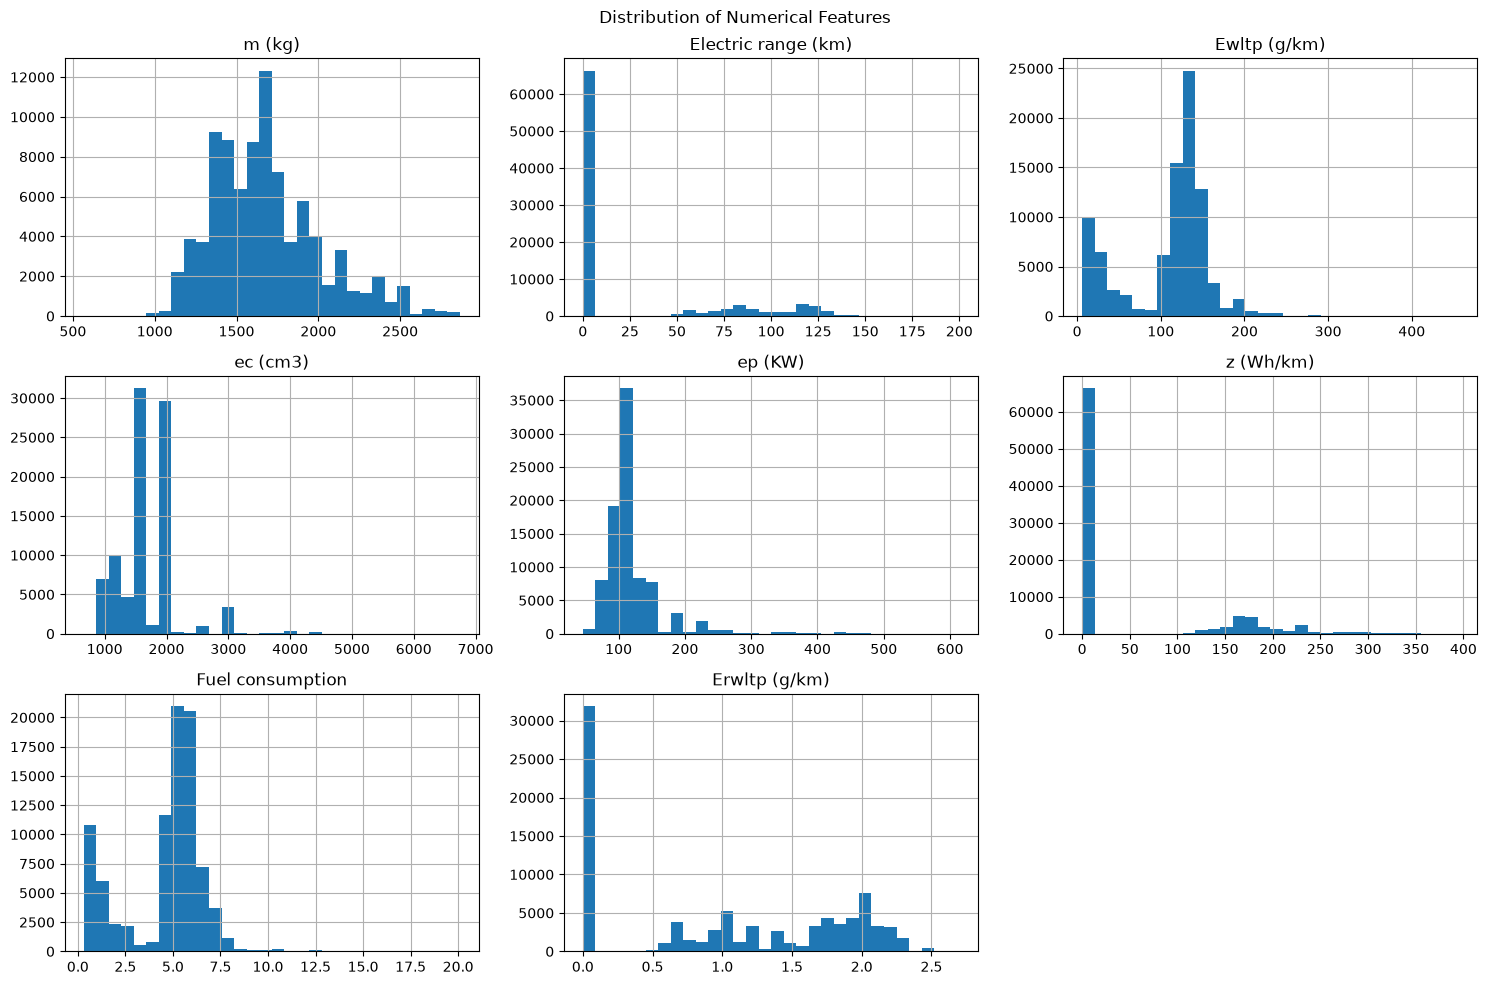

--- Feature Skewness ---
m (kg)                 0.778469
Electric range (km)    1.400653
Ewltp (g/km)          -0.504262
ec (cm3)               1.834814
ep (KW)                3.430411
z (Wh/km)              1.414637
Fuel consumption      -0.506525
Erwltp (g/km)          0.028608
dtype: float64


In [44]:
def dist_graphs():
    num_cols = [
        "m (kg)", "Electric range (km)", "Ewltp (g/km)", "ec (cm3)", "ep (KW)", "z (Wh/km)", "Fuel consumption", "Erwltp (g/km)"]
    
    # Keep only columns that actually exist in your dataset to avoid errors
    existing_num_cols = [col for col in num_cols if col in df_2025.columns]

    # Visual inspection of distributions
    df_2025[existing_num_cols].hist(bins=30, figsize=(15, 10))
    plt.suptitle("Distribution of Numerical Features")
    plt.tight_layout()
    plt.show()

    # Print Skewness to verify outlier presence
    print("--- Feature Skewness ---")
    print(df_2025[existing_num_cols].skew())
    
dist_graphs()

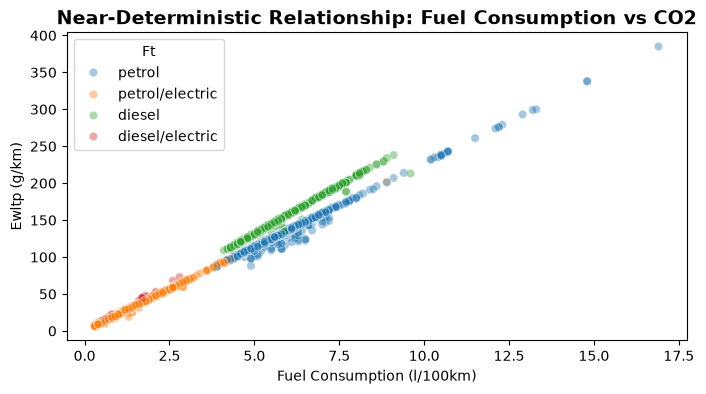

In [45]:
plt.figure(figsize=(8, 4))

combustion_df = df_2025[df_2025['Fuel consumption'] > 0]

sns.scatterplot(
    data=combustion_df.sample(5000, random_state=42), 
    x='Fuel consumption', 
    y='Ewltp (g/km)', 
    hue='Ft',
    alpha=0.4
)
plt.title('Near-Deterministic Relationship: Fuel Consumption vs CO2', fontsize=14, fontweight='bold')
plt.xlabel('Fuel Consumption (l/100km)')
plt.ylabel('Ewltp (g/km)')
plt.show()

## The scatter plot demonstrates a near-perfect deterministic relationship between Fuel Consumption and Ewltp (g/km), separated neatly by fuel-type constants. Including Fuel Consumption introduces catastrophic target leakage, trivialising model training ($R^2 \approx 1.0$) and blinding the algorithm to physical vehicle engineering parameters like mass and power.

## The goal is to build a predictive machine learning model that estimates emissions based on physical vehicle design specs (like weight, engine displacement, and power output)
## The decision to drop:
* Prevents Target Leakage: As the scatter plot clearly demonstrated, Fuel consumption determines $\text{CO}_2$ mathematically. Keeping it means the model isn't predicting emissions—it's just solving a basic stoichiometry formula.
* It Keeps the Model Useful for Real-World Inference: Engineers and planners use ML models to answer questions like "If we build a car with 150 kW power weighing 1,800 kg, what will its $\text{CO}_2$ emissions be?" At the design stage, official laboratory fuel consumption numbers don't exist yet.
* It Forces Learning from Physical Attributes: Once dropped, the model will be forced to learn the actual physical relationships between Equipment_Mass, ec (cm3), ep (KW), and Make_Encoded to predict Ewltp (g/km).

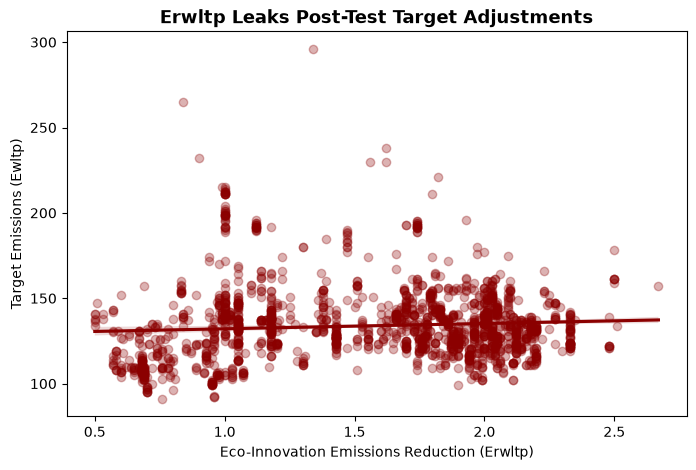

In [46]:
plt.figure(figsize=(8, 5))
sns.regplot(
    data=df_2025[df_2025['Erwltp (g/km)'] > 0].sample(2000, random_state=42),
    x='Erwltp (g/km)', 
    y='Ewltp (g/km)',
    color='darkred',
    scatter_kws={'alpha': 0.3}
)
plt.title('Erwltp Leaks Post-Test Target Adjustments', fontsize=13, fontweight='bold')
plt.xlabel('Eco-Innovation Emissions Reduction (Erwltp)')
plt.ylabel('Target Emissions (Ewltp)')
plt.show()

## Disconnect From Raw Physics
* Cluster Stacking: The plot shows clear vertical stacks at discrete x-axis values like $1.0$, $1.5$, and $2.0\text{ g/km}$, which fits the explanation of official regulatory tiers.
* Target Emissions Range: The explanation states that target emissions span from $110$ to $190+\text{ g/km}$, but the y-axis (Target Emissions Ewltp) clearly ranges from below $100\text{ g/km}$ up to $330+\text{ g/km}$. For instance, at the $1.0\text{ g/km}$ mark on the x-axis, the points span from around $105\text{ g/km}$ up to over $220\text{ g/km}$, and there are outliers reaching $330\text{ g/km}$.
* No Direct Correlation: Across any fixed reduction value (for example, at $1.50\text{ g/km}$), target emissions span from $110\text{ g/km}$ to $190+\text{ g/km}$. The flat, weak trend line shows that Erwltp provides almost no signal regarding baseline physical vehicle attributes (like weight, displacement, or engine power).

## Target Contamination & Regulatory Leakage
* Post-Test Offsets: Under EU regulatory frameworks, Erwltp represents an administrative credit subtracted from a vehicle's certified type-approval baseline.
* Model Corruption: Because Erwltp is calculated after standardised WLTP laboratory testing, including it allows the model to access regulatory adjustment credits rather than learning physical emissions dynamics from physical parameters (Equipment_Mass, ec, ep).

# We must exclude **Fuel consumption** & **Erwltp (g/km)** columns from final feature set since they force the model to rely purely on fundamental design and engineering specifications

## Let's analyse the outliers for our numerical columns:

In [47]:
def outlier_summary():
    num_cols = [
        "m (kg)", 
        "Electric range (km)", 
        "z (Wh/km)", 
        "Ewltp (g/km)", 
        "ec (cm3)", 
        "ep (KW)",
    ]
    
    outlier_rows = []
    
    for col in num_cols:
        series = df_2025[col]
        q1 = series.quantile(0.25)
        q3 = series.quantile(0.75)
        iqr = q3 - q1
        lower_bound = q1 - 1.5 * iqr
        upper_bound = q3 + 1.5 * iqr
    
        outlier_mask = (series < lower_bound) | (series > upper_bound)
    
        outlier_rows.append({
            "column": col,
            "q1": q1,
            "q3": q3,
            "iqr": iqr,
            "lower_bound": lower_bound,
            "upper_bound": upper_bound,
            "outlier_count": outlier_mask.sum(),
            "outlier_pct": round(outlier_mask.mean() * 100, 2),
            "min_outlier": series[outlier_mask].min(),
            "max_outlier": series[outlier_mask].max()
        })
     
    outlier_summary = (
        pd.DataFrame(outlier_rows)
        .set_index("column")
        .round(2)
    )
    
    display(outlier_summary)

outlier_summary()


,q1,q3,iqr,lower_bound,upper_bound,outlier_count,outlier_pct,min_outlier,max_outlier
column,,,,,,,,,
m (kg),1440.0,1866.0,426.0,801.0,2505.0,1449,1.63,565.0,2866.0
Electric range (km),0.0,48.0,48.0,-72.0,120.0,4286,4.82,121.0,200.0
z (Wh/km),0.0,126.0,126.0,-189.0,315.0,541,0.61,316.0,395.0
Ewltp (g/km),92.0,139.0,47.0,21.5,209.5,12020,13.51,6.0,456.0
ec (cm3),1490.0,1969.0,479.0,771.5,2687.5,4179,4.70,658.0,6749.0
ep (KW),100.0,130.0,30.0,55.0,175.0,8393,9.43,46.0,614.0


#### Starting with **m (kg)** column:

**Interpretation**

The lower outliers may correspond to:

    Small city cars.

    Lightweight two-seater vehicles.

    Vehicles with small engines.

    Some electric vehicles, depending on how the dataset defines mass.

The upper outliers may correspond to:

    Large SUVs.

    Luxury vehicles.

    Vans or larger passenger vehicles.

    Plug-in hybrids with heavy battery systems.

    High-performance or large-engine vehicles.

The maximum value of 2815 kg is high, but not automatically impossible for a road vehicle. Similarly, 570 kg could represent a very small vehicle rather than a data error. 


Let's see if that's the case:

In [48]:
mkg_outliers = df_2025[
    (df_2025["m (kg)"] < 813) |
    (df_2025["m (kg)"] > 2485)
].copy()

display(mkg_outliers[[
    "Mk",
    "Cn",
    "m (kg)",
    "Ft",
    "Ewltp (g/km)",
    "ec (cm3)",
    "ep (KW)"
]].sort_values("m (kg)").head(20))

display(mkg_outliers[[
    "Mk",
    "Cn",
    "m (kg)",
    "Ft",
    "Ewltp (g/km)",
    "ec (cm3)",
    "ep (KW)"
]].sort_values("m (kg)", ascending=False).head(20))



,Mk,Cn,m (kg),Ft,Ewltp (g/km),ec (cm3),ep (KW)
89976,CATERHAM,SEVEN S3,565.0,petrol,109.0,658.0,62.0
89974,CATERHAM,SEVEN S3,570.0,petrol,109.0,658.0,62.0
89977,CATERHAM,SEVEN S3,570.0,petrol,109.0,658.0,62.0
89975,CATERHAM,SEVEN S3,570.0,petrol,109.0,658.0,62.0
32562,CATERHAM,SEVEN S3,650.0,petrol,148.0,1999.0,127.0
37157,SECMA,FUN 1600,658.0,petrol,135.0,1598.0,84.0
37158,SECMA,FUN 1600 BUGGY,668.0,petrol,135.0,1598.0,84.0
32567,CATERHAM,SEVEN S3,700.0,petrol,148.0,1999.0,127.0
32565,CATERHAM,SEVEN SV,700.0,petrol,148.0,1999.0,127.0
32563,CATERHAM,SEVEN S3,700.0,petrol,148.0,1999.0,127.0


,Mk,Cn,m (kg),Ft,Ewltp (g/km),ec (cm3),ep (KW)
20015,MERCEDES-AMG,CLASSE G,2866.0,petrol,456.0,3982.0,430.0
35702,PORSCHE,CAYENNE TURBO E-HYBRID,2860.0,petrol/electric,113.0,3996.0,441.0
25346,MERCEDES-BENZ,MAYBACH GLS 600,2825.0,petrol,314.0,3982.0,410.0
25345,MERCEDES-BENZ,MAYBACH GLS 600,2825.0,petrol,312.0,3982.0,410.0
30358,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,19.0,2996.0,294.0
30357,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,18.0,2996.0,294.0
30361,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,19.0,2996.0,294.0
30360,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,19.0,2996.0,294.0
30359,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,19.0,2996.0,294.0
30356,LAND ROVER,RANGE ROVER,2810.0,petrol/electric,18.0,2996.0,294.0


#### So we don't remove **m (kg)** outliers solely because they fall outside the IQR bounds. Vehicle mass is a meaningful predictor of **Ewltp (g/km)**, and removing heavy or lightweight vehicles could make the model less representative.

In [49]:
# 1. Create a Boolean mask: True = row should be investigated / removed
mask_suspicious_phev = (
    (df_2025["Ft"] == "petrol/electric")
    & (df_2025["Electric range (km)"] > 200)
)

# 2. Create a DataFrame containing only those rows
suspicious_phev_range = df_2025.loc[mask_suspicious_phev].copy()

# 3. Display the suspicious records
display(
    suspicious_phev_range[
        [
            "Mk",
            "Cn",
            "Ft",
            "Fm",
            "Electric range (km)",
            "z (Wh/km)",
            "Ewltp (g/km)",
            "ep (KW)",
            "m (kg)",
        ]
    ].sort_values("Electric range (km)", ascending=False)
)

# 4. Count rows and calculate percentage
print("Rows to remove:", mask_suspicious_phev.sum())
print(f"Percentage of all rows: {mask_suspicious_phev.mean() * 100:.4f}%")

# 5. Describe the suspicious electric-range values
print(
    suspicious_phev_range["Electric range (km)"].describe()
)

,Mk,Cn,Ft,Fm,Electric range (km),z (Wh/km),Ewltp (g/km),ep (KW),m (kg)


Rows to remove: 0
Percentage of all rows: 0.0000%
count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: Electric range (km), dtype: float64


#### Next we continue with **z (Wh/km):**

There are no IQR outliers.

Zeros here are structural: 0 Wh/km for petrol or diesel cars generally means they do not consume grid electricity.

A high Wh/km figure can be physically plausible for a large, heavy SUV or performance EV; it is not automatically bad data.



#### Next, we continue with **Ewltp (g/km)**

In [50]:
# Let's inspect the upper tail:

high_co2 = df_2025.loc[
    df_2025["Ewltp (g/km)"] > 199,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "Ewltp (g/km)",
        "Fuel consumption",
        "ec (cm3)",
        "ep (KW)",
        "m (kg)",
    ],
].sort_values("Ewltp (g/km)", ascending=False)

display(high_co2.head(30))

# compare CO2 with Fuel consumptions:
df_2025.groupby("Ft").agg(
    n=("Ewltp (g/km)", "size"),
    median_co2=("Ewltp (g/km)", "median"),
    mean_co2=("Ewltp (g/km)", "mean"),
    max_co2=("Ewltp (g/km)", "max"),
    median_fuel=("Fuel consumption", "median"),
    max_fuel=("Fuel consumption", "max"),
).round(2)

# Examine CO2 by fuel type:
df_2025.groupby("Ft")["Ewltp (g/km)"].describe().round(2)

,Mk,Cn,Ft,Fm,Ewltp (g/km),Fuel consumption,ec (cm3),ep (KW),m (kg)
20015,MERCEDES-AMG,CLASSE G,petrol,M,456.0,20.1,3982.0,430.0,2866.0
37169,FERRARI,FERRARI PUROSANGUE,petrol,M,393.0,17.3,6496.0,529.0,2245.0
37168,FERRARI,FERRARI PUROSANGUE,petrol,M,393.0,17.3,6496.0,529.0,2245.0
37167,FERRARI,FERRARI PUROSANGUE,petrol,M,393.0,17.3,6496.0,529.0,2245.0
36886,FERRARI,812 COMPETIZIONE,petrol,M,385.0,16.9,6496.0,607.0,1740.0
36885,FERRARI,812 COMPETIZIONE,petrol,M,385.0,16.9,6496.0,607.0,1740.0
36884,FERRARI,812,petrol,M,385.0,16.9,6496.0,607.0,1740.0
9,ROLLS-ROYCE,CULLINAN,petrol,M,371.0,16.4,6749.0,420.0,2800.0
36887,FERRARI,812 COMPETIZIONE A,petrol,M,370.0,16.3,6496.0,607.0,1810.0
21489,MERCEDES-BENZ,AMG G 63,petrol,M,369.0,16.2,3982.0,430.0,2595.0


,count,mean,std,min,25%,50%,75%,max
Ft,,,,,,,,
diesel,21515.0,144.79,23.83,106.0,130.0,139.0,149.0,322.0
diesel/electric,998.0,22.31,15.56,11.0,12.0,13.0,43.0,74.0
petrol,44842.0,131.25,23.35,85.0,119.0,129.0,140.0,456.0
petrol/electric,21608.0,29.23,21.97,6.0,11.0,23.0,38.0,350.0


Although 135 values exceeded the IQR upper fence of 199 g/km, manual inspection showed that they represent high-performance and heavy petrol vehicles, including Mercedes-AMG, Ferrari, Lamborghini, Rolls-Royce, Bentley, Aston Martin, and large SUVs. Their CO2 values were consistent with high engine displacement, engine power, vehicle mass, and fuel consumption. Therefore, they were retained as valid observations.

#### Next, **ec (cm3)**

In [51]:
# small lower tail

small_engine = df_2025.loc[
    df_2025["ec (cm3)"] < 771.5,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "ec (cm3)",
        "ep (KW)",
        "m (kg)",
        "Fuel consumption",
        "Ewltp (g/km)",
    ],
].sort_values("ec (cm3)")

display(small_engine.head(30))

# high end
large_engine = df_2025.loc[
    df_2025["ec (cm3)"] > 2687.5,
    [
        "Mk",
        "Cn",
        "Ft",
        "Fm",
        "ec (cm3)",
        "ep (KW)",
        "m (kg)",
        "Fuel consumption",
        "Ewltp (g/km)",
    ],
].sort_values("ec (cm3)", ascending=False)

display(large_engine.head(30))

,Mk,Cn,Ft,Fm,ec (cm3),ep (KW),m (kg),Fuel consumption,Ewltp (g/km)
89974,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,570.0,4.8,109.0
89975,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,570.0,4.8,109.0
89976,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,565.0,4.8,109.0
89977,CATERHAM,SEVEN S3,petrol,M,658.0,62.0,570.0,4.8,109.0


,Mk,Cn,Ft,Fm,ec (cm3),ep (KW),m (kg),Fuel consumption,Ewltp (g/km)
7,ROLLS-ROYCE,BLACK BADGE CULLINAN,petrol,M,6749.0,441.0,2800.0,16.2,367.0
8,ROLLS-ROYCE,CULLINAN,petrol,M,6749.0,420.0,2800.0,16.1,365.0
9,ROLLS-ROYCE,CULLINAN,petrol,M,6749.0,420.0,2800.0,16.4,371.0
11,ROLLS-ROYCE,BLACK BADGE GHOST,petrol,M,6749.0,441.0,2580.0,15.7,355.0
31007,LAMBORGHINI,REVUELTO,petrol/electric,P,6498.0,607.0,1967.0,11.9,276.0
31008,LAMBORGHINI,REVUELTO,petrol/electric,P,6498.0,607.0,1985.0,15.0,350.0
31006,LAMBORGHINI,REVUELTO,petrol/electric,P,6498.0,607.0,1967.0,11.9,276.0
36892,FERRARI,FERRARI 12CILINDRI,petrol,M,6496.0,607.0,1835.0,15.5,353.0
37169,FERRARI,FERRARI PUROSANGUE,petrol,M,6496.0,529.0,2245.0,17.3,393.0
36882,FERRARI,FERRARI DAYTONA SP3,petrol,M,6496.0,614.0,1705.0,16.2,368.0


Although a number of ec (cm3) values lie outside the IQR interval of 771.5 - 2687.5 cm3, inspection showed that lower-tail observations represent lightweight small-engine vehicles, while upper-tail observations are large-displacement luxury and performance vehicles. The associated power, mass, fuel consumption, and WLTP CO2 values are internally consistent. 
Therefore, no engine-capacity observations will be removed or capped.

#### Next, **ep (KW)**

Although a number of ep (KW) values lie outside the IQR interval of 55 - 175 kW, inspection showed that low-power outliers represent small or low-output vehicles, while high-power outliers are performance and luxury vehicles. Power values are consistent with engine capacity, mass, fuel consumption, and WLTP CO2. Therefore, no engine-power observations were removed or capped.

# Now, let's see the summary and the distribution graphs again:

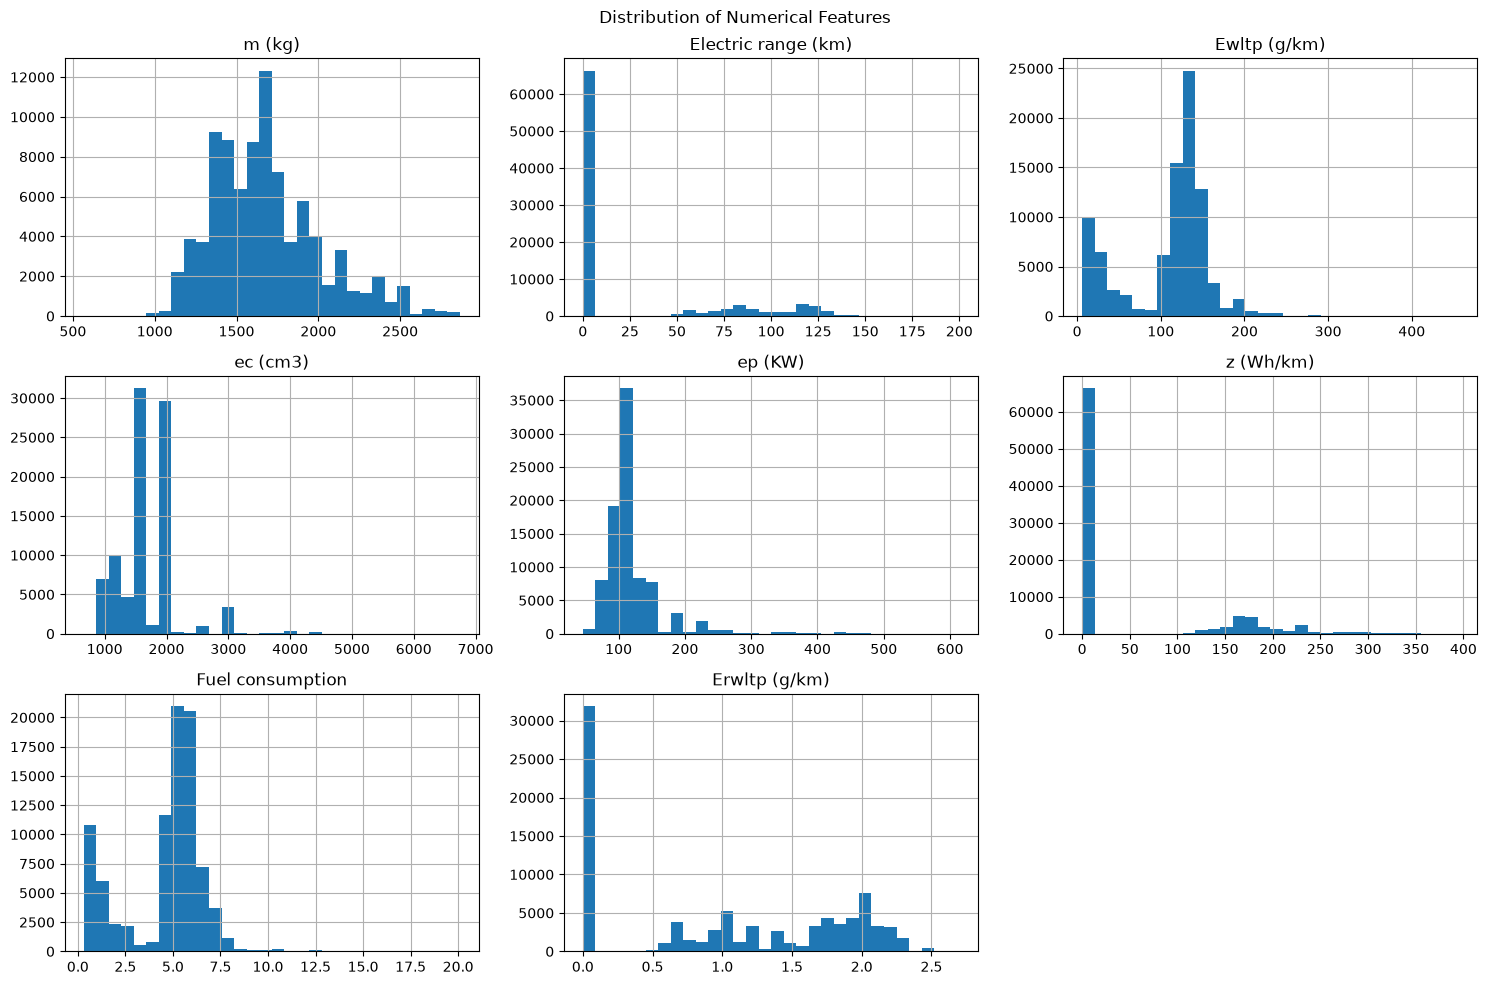

--- Feature Skewness ---
m (kg)                 0.778469
Electric range (km)    1.400653
Ewltp (g/km)          -0.504262
ec (cm3)               1.834814
ep (KW)                3.430411
z (Wh/km)              1.414637
Fuel consumption      -0.506525
Erwltp (g/km)          0.028608
dtype: float64


,dtype,missing_count,missing_pct,zero_count,zero_pct,unique_values,min,q1,median,q3,max
m (kg),float64,0,0.0,0,0.00,1075,565.0,1440.0,1645.0,1866.00,2866.0
Electric range (km),float64,0,0.0,66357,74.59,119,0.0,0.0,0.0,48.00,200.0
z (Wh/km),float64,0,0.0,66357,74.59,258,0.0,0.0,0.0,126.00,395.0
Ewltp (g/km),float64,0,0.0,0,0.00,2181,6.0,92.0,126.0,139.00,456.0
ec (cm3),float64,0,0.0,0,0.00,86,658.0,1490.0,1499.0,1969.00,6749.0
ep (KW),float64,0,0.0,0,0.00,178,46.0,100.0,110.0,130.00,614.0
Erwltp (g/km),float64,0,0.0,31902,35.86,186,0.0,0.0,1.0,1.87,2.7
Fuel consumption,float64,0,0.0,0,0.00,157,0.3,4.1,5.3,5.90,20.1


Shape: (88963, 23)

Dtypes:
 VFN                        str
Mh                         str
Tan                        str
T                          str
Va                         str
Ve                         str
Mk                         str
Cn                         str
Ct                         str
m (kg)                 float64
Mt                     float64
Ft                         str
Fm                         str
ec (cm3)               float64
ep (KW)                float64
z (Wh/km)              float64
IT                         str
Erwltp (g/km)          float64
Fuel consumption       float64
RLFI                       str
Electric range (km)    float64
r                        int64
Ewltp (g/km)           float64
dtype: object

NaN counts:
 VFN                     0
Mh                      0
Tan                     0
T                      19
Va                      0
Ve                      1
Mk                      0
Cn                      0
Ct                    

In [52]:
dist_graphs()

def summary():
    
    num_cols = [
        "m (kg)", 
        "Electric range (km)", 
        "z (Wh/km)", 
        "Ewltp (g/km)", 
        "ec (cm3)", 
        "ep (KW)", 
        "Erwltp (g/km)",
        "Fuel consumption",
    ]
    
    preprocessing_summary = pd.DataFrame({
        "dtype": df_2025[num_cols].dtypes.astype(str),
        "missing_count": df_2025[num_cols].isna().sum(),
        "missing_pct": (df_2025[num_cols].isna().mean() * 100).round(2),
        "zero_count": (df_2025[num_cols] == 0).sum(),
        "zero_pct": ((df_2025[num_cols] == 0).mean() * 100).round(2),
        "unique_values": df_2025[num_cols].nunique(),
        "min": df_2025[num_cols].min(),
        "q1": df_2025[num_cols].quantile(0.25),
        "median": df_2025[num_cols].median(),
        "q3": df_2025[num_cols].quantile(0.75),
        "max": df_2025[num_cols].max()
    }).round(2)
    
    display(preprocessing_summary)

summary()

print("Shape:", df_2025.shape)
print("\nDtypes:\n", df_2025.dtypes)
print("\nNaN counts:\n", df_2025.isna().sum())
print("\nTarget stats:\n", df_2025["Ewltp (g/km)"].describe())

## Now we need to split train and test so that we encode the categorical columns amd implement standardization/normalization on the numerical ones.

### Let's export our dataframe:

In [53]:
df_2025.to_csv("../data/processed/EU/2025_FR_cleaned_final.csv", index = False)


In [54]:
df_2025.describe(include='all')

,VFN,Mh,Tan,T,Va,Ve,Mk,Cn,Ct,m (kg),...,ec (cm3),ep (KW),z (Wh/km),IT,Erwltp (g/km),Fuel consumption,RLFI,Electric range (km),r,Ewltp (g/km)
count,88963,88963,88963,88944,88963,88962,88963,88963,88963,88963.000000,...,88963.000000,88963.000000,88963.000000,88963,88963.000000,88963.000000,88963,88963.000000,88963.000000,88963.000000
unique,1958,63,1540,299,1364,5527,54,710,1,NaN,...,NaN,NaN,NaN,73,NaN,NaN,1000,NaN,NaN,NaN
top,IP-HNA1M2PDB1A_000-VF1,BMW AG,E1*2007/46*1909*29,U1X,ACDXDBX0,FAV500L0,BMW,TIGUAN,M1,NaN,...,NaN,NaN,NaN,none,NaN,NaN,RL-DQ381_7F_23_005-WVW,NaN,NaN,NaN
freq,1343,14116,1260,3547,3512,1905,12837,2659,88963,NaN,...,NaN,NaN,NaN,31902,NaN,NaN,2236,NaN,NaN,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1678.900993,...,1678.440857,120.881861,48.469442,NaN,0.996706,4.587396,NaN,24.005036,14.862617,108.524138
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,329.635443,...,486.511334,48.989321,86.224445,NaN,0.854424,2.172849,NaN,43.009581,111.885151,52.165403
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,565.000000,...,658.000000,46.000000,0.000000,NaN,0.000000,0.300000,NaN,0.000000,1.000000,6.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1440.000000,...,1490.000000,100.000000,0.000000,NaN,0.000000,4.100000,NaN,0.000000,1.000000,92.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1645.000000,...,1499.000000,110.000000,0.000000,NaN,1.000000,5.300000,NaN,0.000000,1.000000,126.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1866.000000,...,1969.000000,130.000000,126.000000,NaN,1.870000,5.900000,NaN,48.000000,4.000000,139.000000


# Summary: Vehicle CO2 Emissions Data Preparation

## 1. Package Setup and Data Loading

The required Python data-science and machine-learning libraries were imported, including `pandas`, `numpy`, `matplotlib`, `seaborn`, scikit-learn tools, `joblib`, and `category_encoders`.

The cleaned 2025 France vehicle dataset was loaded from `2025_FR_cleaned.csv`.

The dataset initially contained **89941 rows and 22 columns**. The non-predictive `r` column was removed because it did not provide useful information for predicting CO₂ emissions.

---

## 4. Fuel Category Filtering

The distributions of fuel type (`Ft`) and fuel mode (`Fm`) were inspected before filtering.

The dataset retained the primary fuel categories:

- Petrol
- Petrol/electric
- Diesel
- Diesel/electric

Low-frequency fuel categories were removed:

- `e85`
- `lpg`

These categories represented only a small proportion of the data and could introduce unstable or unreliable patterns during model training.

---

## 5. Target Leakage Prevention

Fuel consumption and `Erwltp` was suspected for target leakage.

Fuel consumption has a direct physical and stoichiometric relationship with CO₂ emissions. Including it could allow the model to predict emissions using an overly direct proxy instead of learning meaningful relationships from vehicle characteristics, such as:

- Vehicle mass
- Engine displacement
- Engine power
- Fuel type
- Vehicle manufacturer

---

## 6. Outlier and Data-Quality Handling

Summary statistics and numerical distributions were examined to understand feature ranges, skewness, and possible anomalies.

Histograms were used to visualize the distributions of numerical variables.

